# Step 2: explore the Green Taxi data

**Why:** before adding up revenue per day, check the two columns that matter: *when* the trip happened (`lpep_pickup_datetime`) and *what was paid* (`total_amount`). Every cleaning rule in `dbt/models/staging/stg_green_trips.sql` comes from a finding in this notebook.

This notebook is for exploring only. The pipeline in `src/green_taxi/` and `dbt/` runs without it.

Run `uv run green-taxi download` first so the files are in `data/raw/`.

In [1]:
import pandas as pd

from green_taxi.config import DEFAULT_MONTHS, RAW_DIR, source_filename

PERIOD_START = pd.Timestamp("2025-01-01")
PERIOD_END = pd.Timestamp("2025-04-01")  # exclusive

frames = []
for month in DEFAULT_MONTHS:
    frame = pd.read_parquet(RAW_DIR / source_filename(month))
    frame["source_month"] = month
    frames.append(frame)
trips = pd.concat(frames, ignore_index=True)

trips.groupby("source_month").size().rename("rows").to_frame().assign(
    total=lambda d: d["rows"].sum()
)

,rows,total
source_month,,
2025-01,48326,146486
2025-02,46621,146486
2025-03,51539,146486


## Columns and types

Green taxis use `lpep_*` timestamps (yellow taxis use `tpep_*`), so the course's yellow-taxi SQL can't be copied as is. `cbd_congestion_fee` is new in 2025 (Manhattan congestion pricing started on 5 January 2025).

In [2]:
trips.dtypes.rename("dtype").to_frame().assign(nulls=trips.isna().sum())

,dtype,nulls
VendorID,int32,0
lpep_pickup_datetime,datetime64[us],0
lpep_dropoff_datetime,datetime64[us],0
store_and_fwd_flag,str,7902
RatecodeID,float64,7902
PULocationID,int32,0
DOLocationID,int32,0
passenger_count,float64,7902
trip_distance,float64,0
fare_amount,float64,0


## When did the trip happen?

Each monthly file should only contain trips from that month. Check the pickup range per file and count trips outside Jan 1 to Mar 31, 2025.

In [3]:
pickup = trips["lpep_pickup_datetime"]
trips.groupby("source_month")["lpep_pickup_datetime"].agg(["min", "max"])

,min,max
source_month,,
2025-01,2024-12-25 23:13:15,2025-02-05 18:46:24
2025-02,2025-01-31 22:34:50,2025-03-01 23:29:24
2025-03,2025-02-25 18:10:10,2025-04-01 23:41:29


In [4]:
in_period = (pickup >= PERIOD_START) & (pickup < PERIOD_END)
in_own_month = pickup.dt.strftime("%Y-%m") == trips["source_month"]

print(f"outside their file's month:  {(~in_own_month).sum():>4}")
print(f"outside Jan 1 to Mar 31 2025: {(~in_period).sum():>4}")
print(f"days with trips, all rows:    {pickup.dt.date.nunique():>4}")
print(f"days with trips, in period:   {pickup[in_period].dt.date.nunique():>4}")
trips.loc[~in_period, "lpep_pickup_datetime"].dt.date.value_counts().sort_index()

outside their file's month:    73
outside Jan 1 to Mar 31 2025:   11
days with trips, all rows:      94
days with trips, in period:     90


lpep_pickup_datetime
2024-12-25    1
2024-12-29    1
2024-12-31    4
2025-04-01    5
Name: count, dtype: int64

## What was paid?

`total_amount` is the full charge: fare, extras, MTA tax, tip, tolls and surcharges. Look at its range, zeros, negatives and very large values.

In [5]:
amount = trips["total_amount"]
amount.describe().round(2)

count    146486.00
mean         23.18
std          16.49
min        -473.10
25%          13.80
50%          18.90
75%          27.18
max         642.14
Name: total_amount, dtype: float64

In [6]:
summary = pd.DataFrame(
    {
        "rows": [
            (amount < 0).sum(),
            (amount == 0).sum(),
            (amount > 500).sum(),
            amount.isna().sum(),
        ],
        "sum": [
            amount[amount < 0].sum(),
            0.0,
            amount[amount > 500].sum(),
            0.0,
        ],
    },
    index=["negative", "zero", "over $500", "missing"],
).round(2)
summary

,rows,sum
negative,478,-6462.61
zero,254,0.00
over $500,2,1221.64
missing,0,0.00


Negative amounts are refunds, disputes and voided trips. Which payment types do they have? (1 = credit card, 2 = cash, 3 = no charge, 4 = dispute, 5 = unknown, 6 = voided.)

In [7]:
pd.crosstab(
    trips["payment_type"].fillna(-1).astype(int),
    amount < 0,
    margins=True,
).rename(columns={False: "amount >= 0", True: "amount < 0"}).rename(
    index={-1: "missing"}
)

total_amount,amount >= 0,amount < 0,All
payment_type,,,
missing,7902,0,7902
1,103154,0,103154
2,34047,14,34061
3,703,337,1040
4,199,127,326
5,3,0,3
All,146008,478,146486


In [8]:
duplicates = trips.drop(columns="source_month").duplicated().sum()
print(f"exact duplicate rows: {duplicates}")

exact duplicate rows: 0


## Revenue per day, before and after cleaning

A first look at the number we're building: net revenue (charges minus refunds) per pickup day, in the period only.

In [9]:
clean = trips.loc[in_period]
daily = (
    clean.assign(service_date=clean["lpep_pickup_datetime"].dt.date)
    .groupby("service_date")
    .agg(
        trips=("total_amount", "size"),
        gross_revenue=("total_amount", lambda s: s[s >= 0].sum()),
        refunds=("total_amount", lambda s: s[s < 0].sum()),
        net_revenue=("total_amount", "sum"),
    )
    .round(2)
)
print(
    f"rows before cleaning: {len(trips):,}  after: {len(clean):,}  dropped: {len(trips) - len(clean)}"
)
print(f"days: {len(daily)}  net revenue: ${daily['net_revenue'].sum():,.2f}")
daily.head()

rows before cleaning: 146,486  after: 146,475  dropped: 11
days: 90  net revenue: $3,395,290.56


,trips,gross_revenue,refunds,net_revenue
service_date,,,,
2025-01-01,1001,25195.01,-118.50,25076.51
2025-01-02,1516,34278.18,-21.35,34256.83
2025-01-03,1525,36533.99,-16.30,36517.69
2025-01-04,1249,27977.60,-108.40,27869.20
2025-01-05,1129,25838.19,-14.50,25823.69


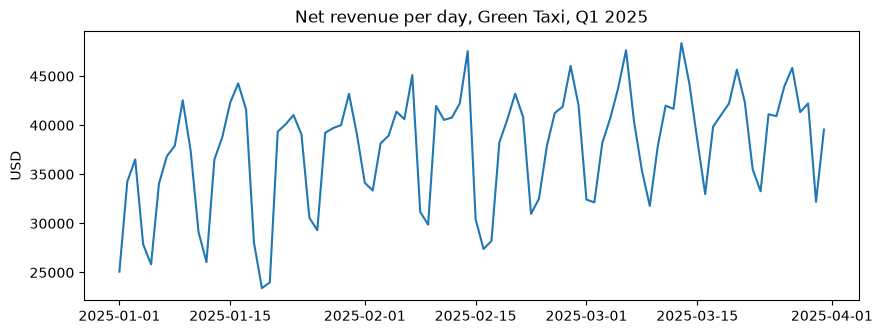

In [10]:
ax = daily["net_revenue"].plot(
    figsize=(10, 3.5), title="Net revenue per day, Green Taxi, Q1 2025"
)
ax.set_xlabel("")
ax.set_ylabel("USD");

## Findings and the cleaning rules they create

| Finding | Rule in the pipeline |
|---|---|
| A few trips are dated outside Jan 1 to Mar 31, 2025 (e.g. December 2024) | keep only pickups in the period, so the result has exactly 90 days |
| Some trips in a month's file belong to the neighbouring month (e.g. a Jan 31 trip in the February file) | group by pickup date across all files, not per file |
| Negative `total_amount` rows are refunds, disputes and voids | keep them, and report `gross_revenue`, `refunds` and `net_revenue` separately |
| Zero-amount trips exist | count them as trips with $0 revenue |
| `payment_type` is missing for some trips, but their amounts look normal | keep them |
| A couple of trips are over $500 | keep them, and list them in the quality report |
| No exact duplicate rows | no deduplication step |
| Green columns are `lpep_*`, and there's a new `cbd_congestion_fee` | write the staging SQL for green taxis, not yellow |

**Revenue definition:** `net_revenue` for a day = sum of `total_amount` for trips picked up that day. `gross_revenue` and `refunds` sit next to it.